# Sea ice area and concentration for ACCESS-OM3

This notebook compares Arctic and Antarctic sea ice area and concentration from an OM3 run with NSIDC observations, other OM3 runs and ACCESS-OM2.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/"
nbname = "SeaIce_area.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import intake

from dask.distributed import Client

import xarray as xr
import numpy as np
from datetime import timedelta
import xesmf

from exptdata_access import get_exptname_from_path

# plotting
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean.cm as cmo
import matplotlib.lines as mlines

In [5]:
IAF = esm_file.find('iaf') > 0

In [6]:
client = Client(threads_per_worker=1)
print(client.dashboard_link)

http://127.0.0.1:8787/status


# Data

Load the model sea ice concentration and grid cell areas, and the NSIDC passive microwave observations.

## Open the intake-esm datastore & model dataset for sea ice concentration

Open the intake-esm datastore for the main OM3 experiment (`esm_file`) and load the monthly sea ice concentration (`aice_m`) and grid cell area (`tarea`).

In [7]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)


In [8]:
variable = "aice_m"
area_variable = "tarea"

In [9]:
dset = datastore.search(variable=variable, frequency="1mon").to_dask()
dset = dset.chunk({'time':12})

# CICE static grid file: T-cell areas, land mask and lon/lat (TLON/TLAT coordinates)
grid = datastore.search(variable=[area_variable, "tmask"], frequency="fx", realm="seaIce", path = ".*output000.*").to_dask()

We use years 1979 to 2008 for the climatologies

In [10]:
if IAF:
    t_slice = slice('1979','2008') #manually pick some years in both om2 & 3 experiments
    obs_t_slice = t_slice
else:
    years = np.unique(dset.time.dt.year)[-10:]
    t_slice = slice(str(years[0]),str(years[-1]))
    # RYF model years don't correspond to real years, so the observations and the
    # (IAF) comparison runs use the IAF climatology period instead
    obs_t_slice = slice('1979','2008')
t_slice, obs_t_slice

(slice('1900', '1909', None), slice('1979', '2008', None))

## Observations

Load the NOAA/NSIDC sea ice concentration Climate Data Record (G02202 v6) monthly fields for each hemisphere, and the matching NSIDC polar-stereographic grid cell areas.

In [11]:
sh_obs = xr.open_mfdataset('/g/data/av17/access-nri/OM3/CDR_G02202_V6/south/monthly/sic_pss25*.nc', data_vars='minimal', compat='override', coords='minimal', parallel=True).chunk({'time':12})

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14abe336acf0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ba4e615b20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14c50ef79ac0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a7f2dd9bb0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x154ce59de570>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1532c89bcfb0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1530be097a40>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1530bc39c530>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1532c87f0b00>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1532c6705fd0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [12]:
nh_obs = xr.open_mfdataset('/g/data/av17/access-nri/OM3/CDR_G02202_V6/north/monthly/sic_psn25*.nc', data_vars='minimal', compat='override', coords='minimal', parallel=True).chunk({'time':12})

In [13]:
def add_nsidc_areas(filename, obs_ds):
    """
    Load the unformatted binary file with grid areas from NSIDC, and add as a coordinate to an xarray dataset
    """
    # The pss25/psn25 area files (distributed with V5) are for the same 25 km
    # polar-stereographic grids as the V6 data; values are stored as integer km^2 * 1000
    areas = np.fromfile(filename, dtype=np.int32).reshape(
        obs_ds.cdr_seaice_conc_monthly.isel(time=0).shape
    )
    return obs_ds.assign_coords(area=(("y", "x"), areas * 1e3))  # convert to m^2

In [14]:
sh_obs = add_nsidc_areas("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-sh/pss25area_v3.dat", sh_obs)
nh_obs = add_nsidc_areas("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-nh/psn25area_v3.dat", nh_obs)

# Calculation

Calculate Arctic and Antarctic sea ice area timeseries (concentration times grid cell area, summed over cells with at least 15% concentration) for the model and the observations.

In [15]:
def seaice_area(sic, area, tlat):
    """Arctic and Antarctic sea ice area (m^2) timeseries from a model's monthly sea ice concentration"""
    # Discard concentrations below 15% -- the standard sea ice extent/area
    # threshold -- before summing into the area timeseries
    seaice = sic.where(sic >= 0.15) * area
    return {
        "Arctic": seaice.where(tlat > 0).sum(['nj','ni']).compute(),
        "Antarctic": seaice.where(tlat < 0).sum(['nj','ni']).compute(),
    }

sic = dset[variable]

# label -> {"Arctic": timeseries, "Antarctic": timeseries}, sea ice area in m^2
main_label = f"OM3 {get_exptname_from_path(esm_file)}"
model_areas = {
    main_label: seaice_area(sic, grid[area_variable].load(), grid.TLAT.load())
}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 69.42 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 69.42 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [16]:
sh_sic = sh_obs['cdr_seaice_conc_monthly']
nh_sic = nh_obs['cdr_seaice_conc_monthly']

# Discard concentrations below 15% -- the standard sea ice extent/area
# threshold -- before summing into the area timeseries (m^2)
obs_areas = {
    "Arctic": (nh_sic.where(nh_sic >= 0.15) * nh_obs.area.load()).sum(['y','x']).compute(),
    "Antarctic": (sh_sic.where(sh_sic >= 0.15) * sh_obs.area.load()).sum(['y','x']).compute(),
}

In [17]:
# Blank out months with missing or bad observations
bad_obs_months = {"Arctic": ["1984-07", "1987-12", "1988-01"], "Antarctic": ["1987-12", "1988-01"]}
for region, months in bad_obs_months.items():
    for month in months:
        obs_areas[region].loc[{"time": month}] = np.nan

## Comparison runs

Sea ice area timeseries, calculated the same way as above, for other OM3 runs and an ACCESS-OM2 0.25° run (from the ACCESS-NRI intake catalog).

In [18]:
# Other OM3 runs to compare against the main experiment (esm_file)
compare_esm_files = [
    "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json",
]

for f in compare_esm_files:
    run_datastore = intake.open_esm_datastore(f, columns_with_iterables=COLUMNS_WITH_ITERABLES)
    run_sic = run_datastore.search(variable=variable, frequency="1mon").to_dask().chunk({'time':12})[variable]
    run_area = run_datastore.search(variable=area_variable, frequency="fx", realm="seaIce", path = ".*output000.*").to_dask()[area_variable].load()
    model_areas[f"OM3 {get_exptname_from_path(f)}"] = seaice_area(run_sic, run_area, run_area.TLAT)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 15.58 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 15.58 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [19]:
# ACCESS-OM2 0.25deg run from the ACCESS-NRI intake catalog
om2_exp = "025deg_jra55_iaf_omip2_cycle1"
catalog = intake.cat.access_nri

om2_search = catalog[om2_exp].search(variable=variable, frequency="1mon")
om2_search.esmcat.aggregation_control.groupby_attrs = ['frequency']  # as in SeaIce_Vol.ipynb
sic_om2 = om2_search.to_dask(
    xarray_open_kwargs=dict(chunks={"time": 12}, decode_timedelta=True),
    xarray_combine_by_coords_kwargs=dict(compat="override", data_vars="minimal", coords="minimal"),
)[variable]

# OM2 CICE timestamps are at the end of each averaging period (00:00 on the 1st of
# the following month) -- shift back into the month being averaged
sic_om2["time"] = sic_om2.time.to_pandas() - timedelta(minutes=1)

# Sea ice grid cell area and latitude -- static, and written to every CICE history
# file, so take them from the first one
om2_grid = xr.open_dataset(om2_search.df.path.iloc[0])
model_areas[f"OM2 {om2_exp}"] = seaice_area(sic_om2, om2_grid[area_variable].load(), om2_grid.TLAT.load())

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca6334c3e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca63444f20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca635f91c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca62b9a420>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca632946b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca63130770>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ca61cfb980>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


# Plot

Compare the seasonal cycle, annual mean, and 12-month rolling minimum, mean and maximum of Arctic and Antarctic sea ice area against observations.

In [20]:
font = {'size':13}

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md successfully.


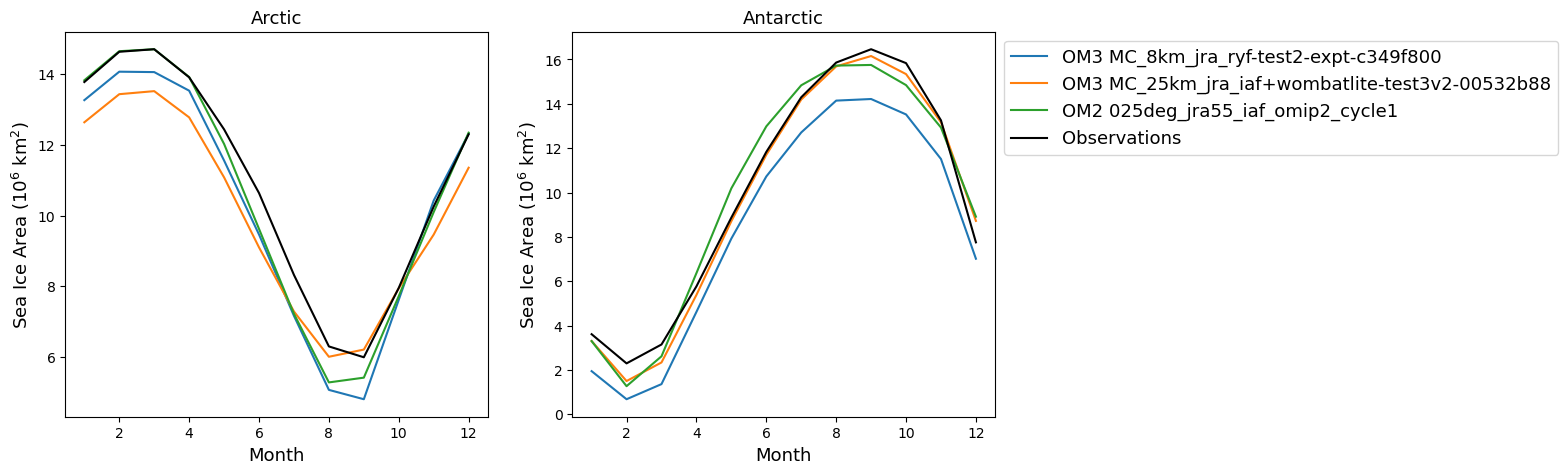

In [21]:
plt.figure(figsize=(12,5))

for i, region in enumerate(["Arctic", "Antarctic"], start=1):
    plt.subplot(1,2,i)
    for label, areas in model_areas.items():
        (areas[region].sel(time=t_slice if label == main_label else obs_t_slice).groupby('time.month').mean('time') / 1e12).plot(label = label)      # convert from m^2 -> 10^6 km^2
    (obs_areas[region].sel(time=obs_t_slice).groupby('time.month').mean('time') / 1e12).plot(label = 'Observations',c='k')

    plt.xlabel('Month',font)
    plt.ylabel('Sea Ice Area (10$^6$ km$^2$)',font)
    plt.title(region,font)

plt.legend(prop=font,loc='upper left', bbox_to_anchor=(1, 1))

# save before plt.show(), which closes the figure
mkmd.savefig(plt.gcf(), "Sea Ice Area", "Seasonal sea ice area for Arctic and Antarctic, compared with other OM3 runs and ACCESS-OM2. [GitHub issue: Sea ice annual cycle](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/21)", dpi=300)
plt.show()

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md successfully.


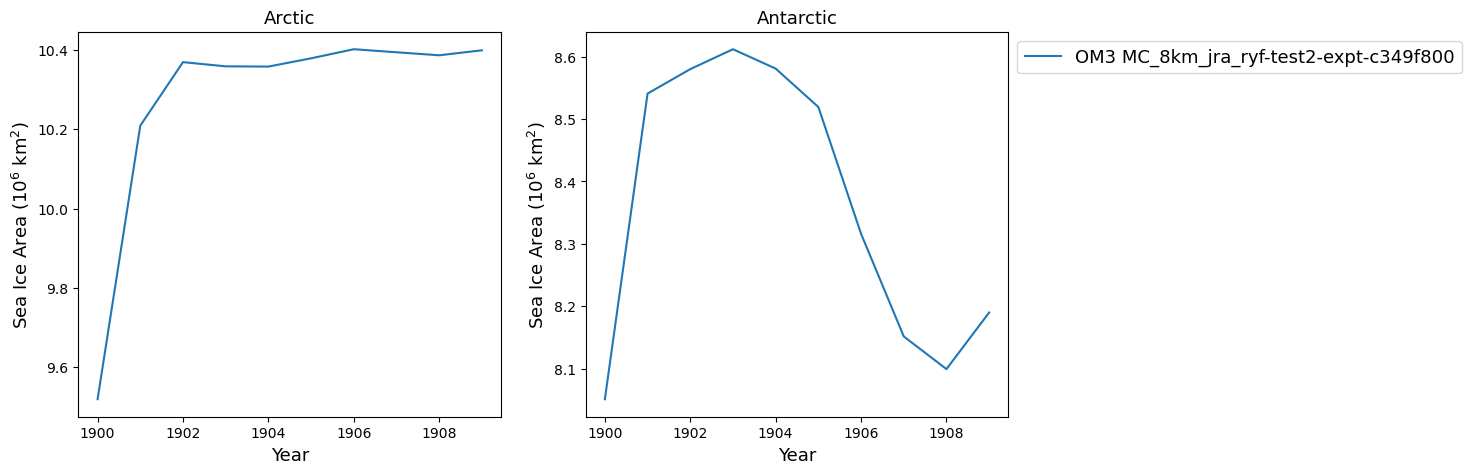

In [22]:
plt.figure(figsize=(12,5))

for i, region in enumerate(["Arctic", "Antarctic"], start=1):
    plt.subplot(1,2,i)
    for label, areas in model_areas.items():
        if not IAF and label != main_label:
            continue  # RYF model years don't correspond to the real years of the other runs
        (areas[region].groupby('time.year').mean('time') / 1e12).plot(label = label)      # convert from m^2 -> 10^6 km^2
    if IAF:
        (obs_areas[region].groupby('time.year').mean('time')[:-1] / 1e12).plot(label = 'Observations',c='k')

    plt.xlabel('Year',font)
    plt.ylabel('Sea Ice Area (10$^6$ km$^2$)',font)
    plt.title(region,font)

plt.legend(prop=font,loc='upper left', bbox_to_anchor=(1, 1))

mkmd.savefig(plt.gcf(), "Sea Ice Area", "Annual mean sea ice area timeseries for Arctic and Antarctic, compared with other OM3 runs and ACCESS-OM2. [GitHub issue: Sea ice extent time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/20)", dpi=300)
plt.show()

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md successfully.


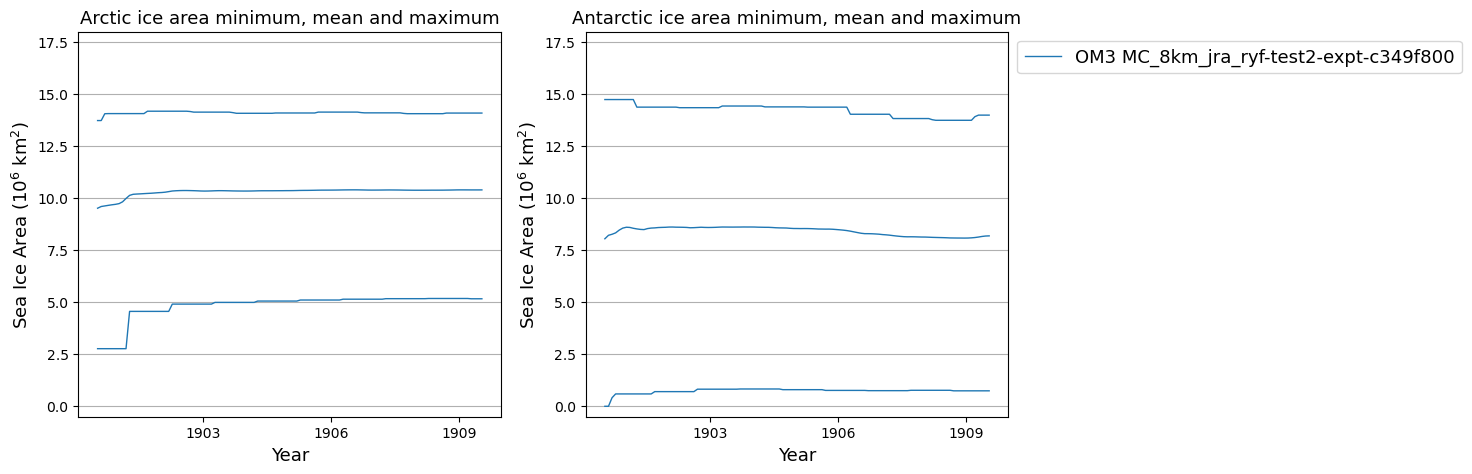

In [23]:
import nc_time_axis  # noqa: lets plt.plot handle cftime times (e.g. noleap RYF runs)

def plot_rolling_min_mean_max(area, label, color=None):
    """Plot the 12-month centred rolling maximum, mean and minimum of a monthly area timeseries, in one colour"""
    rolling = (area / 1e12).rolling(time=12, center=True)      # convert from m^2 -> 10^6 km^2
    for i, stat in enumerate([rolling.max(), rolling.mean(), rolling.min()]):
        line, = plt.plot(area.time[6:-5], stat[6:-5], color=color, linewidth=1, label=label if i == 0 else None)
        color = line.get_color()

plt.figure(figsize=(12,5))

for i, region in enumerate(["Arctic", "Antarctic"], start=1):
    plt.subplot(1,2,i)
    for label, areas in model_areas.items():
        if not IAF and label != main_label:
            continue  # RYF model years don't correspond to the real years of the other runs
        plot_rolling_min_mean_max(areas[region], label)
    if IAF:
        plot_rolling_min_mean_max(obs_areas[region], 'Observations', color='k')

    plt.ylim(ymin=-0.5,ymax=18)
    plt.grid(axis='y')
    plt.xlabel('Year',font)
    plt.ylabel('Sea Ice Area (10$^6$ km$^2$)',font)
    plt.title(f'{region} ice area minimum, mean and maximum',font)

plt.legend(prop=font,loc='upper left', bbox_to_anchor=(1, 1))

mkmd.savefig(plt.gcf(), "Sea Ice Area", "Sea ice area minimum, mean and maximum timeseries, compared with other OM3 runs and ACCESS-OM2. [GitHub issue: Sea ice extent time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/20)", dpi=300)
plt.show()

## Regrid model output to the observational grid

To compare spatial patterns of sea ice concentration, a monthly climatology (over `t_slice`) of the OM3 output on its native curvilinear tripole grid is regridded onto each hemisphere's NSIDC polar-stereographic grid using `xesmf`.

In [24]:
from scipy.ndimage import distance_transform_edt

def fill_nan_nearest(arr):
    """Fill NaNs with the value of the nearest non-NaN grid cell."""
    nan_mask = np.isnan(arr)
    nearest = distance_transform_edt(nan_mask, return_distances=False, return_indices=True)
    return arr[tuple(nearest)]

# Native model grid (tripole) coordinates and land mask, from the CICE grid file.
# TLON/TLAT are NaN wherever tmask is NaN (masked-out cells); those points are
# excluded from regridding via the mask below, but xesmf still needs a valid
# (if arbitrary) position for every grid point, so fill with the nearest
# defined neighbour rather than leaving NaN -- feeding NaN coordinates into
# the regridder corrupts weights for nearby *valid* cells too, which otherwise
# shows up as a spurious streak cutting across the Arctic in the regridded field.
tlat = grid.TLAT.values 
tlon = grid.TLON.values 
tlon_filled = fill_nan_nearest(tlon)
tlat_filled = fill_nan_nearest(tlat)
native_mask = np.nan_to_num(grid.tmask.values, nan=0.0).astype(int)

# ESMF's bilinear stencil search is unreliable for source cells within ~0.5 deg
# of the true pole (a coordinate singularity where a rectangular lon/lat stencil
# isn't well defined) -- left unmasked this produces a spurious line connecting
# opposite sides of the Arctic in the regridded field. Excluding the handful of
# cells immediately around the pole makes ESMF fall back to the next ring out.
native_mask[tlat > 89.5] = 0

sic_native = sic.assign_coords(lon=(("nj", "ni"), tlon_filled), lat=(("nj", "ni"), tlat_filled))
sic_native["mask"] = (("nj", "ni"), native_mask)

# NSIDC polar-stereographic grid lon/lat (same x/y grid as sh_obs & nh_obs)
sh_ancillary = xr.open_dataset("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-sh/G02202-ancillary-pss25-v05r00.nc")
nh_ancillary = xr.open_dataset("/g/data/av17/access-nri/OM3/CDR_G02202_V5/NSIDC-G02202-nh/G02202-ancillary-psn25-v05r00.nc")

sh_target_grid = xr.Dataset(coords={"lon": sh_ancillary.longitude, "lat": sh_ancillary.latitude})
nh_target_grid = xr.Dataset(coords={"lon": nh_ancillary.longitude, "lat": nh_ancillary.latitude})

regridder_sh = xesmf.Regridder(sic_native, sh_target_grid, method="bilinear", periodic=True, ignore_degenerate=True)
regridder_nh = xesmf.Regridder(sic_native, nh_target_grid, method="bilinear", periodic=True, ignore_degenerate=True)

In [25]:
# one month per chunk and computed before regridding: 12-month chunks kill the dask workers at 8km
sic_native_clim = sic_native.sel(time=t_slice).chunk({"time": 1}).groupby("time.month").mean("time").load()

sh_model_clim = regridder_sh(sic_native_clim).assign_coords(x=sh_ancillary.x, y=sh_ancillary.y).compute()
nh_model_clim = regridder_nh(sic_native_clim).assign_coords(x=nh_ancillary.x, y=nh_ancillary.y).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 221.72 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


## March and September concentration climatology and bias

Monthly climatologies of the observations over the same period (`t_slice`) are subtracted from the regridded model climatology to give the model bias in sea ice concentration.

In [26]:
sh_obs_clim = sh_sic.sel(time=obs_t_slice).groupby("time.month").mean("time").compute()
nh_obs_clim = nh_sic.sel(time=obs_t_slice).groupby("time.month").mean("time").compute()

sh_bias = sh_model_clim - sh_obs_clim
nh_bias = nh_model_clim - nh_obs_clim

In [27]:
# Map projections and extents for the bias and concentration maps below.
# Exact NSIDC polar-stereographic projections (EPSG:3411 North / EPSG:3412 South).
# Plotting/contouring directly in each grid's native x/y (metres) avoids the
# spurious contour lines that appear when contouring a curvilinear lon/lat grid
# that wraps around at the pole.
polar_globe = ccrs.Globe(semimajor_axis=6378273, semiminor_axis=6356889.449)
nh_crs = ccrs.Stereographic(central_latitude=90, central_longitude=-45, true_scale_latitude=70, globe=polar_globe)
sh_crs = ccrs.Stereographic(central_latitude=-90, central_longitude=0, true_scale_latitude=-70, globe=polar_globe)

nh_extent = [-180, 180, 55, 90]
sh_extent = [-180, 180, -90, -55]

## March and September concentration bias maps

Map the March and September sea ice concentration bias (OM3 minus observations) in each hemisphere, with the 15% and 80% concentration contours from both.

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md successfully.


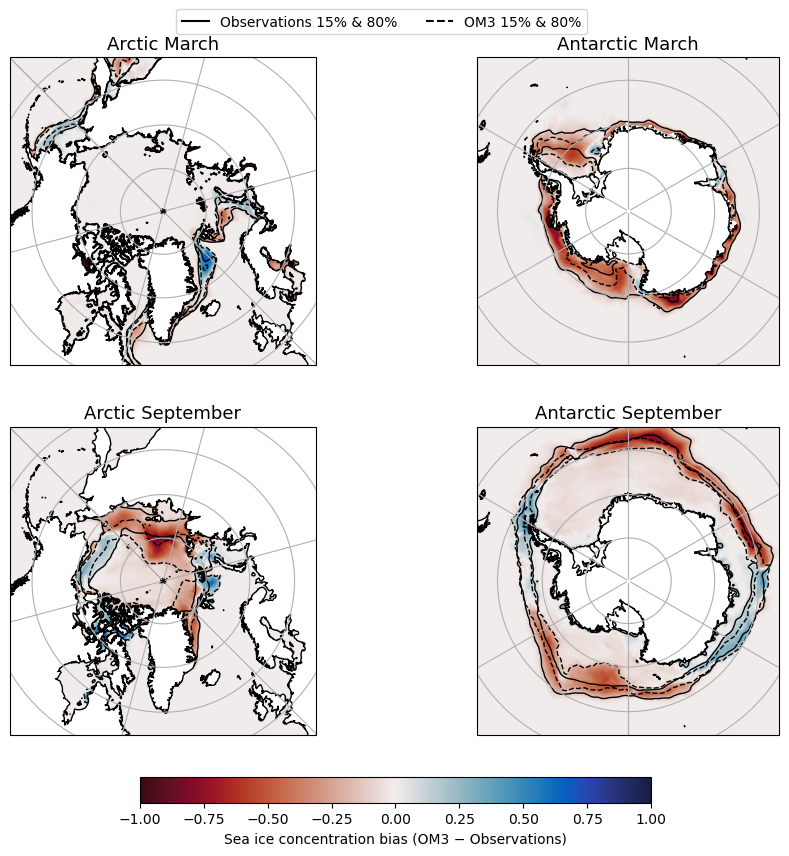

In [28]:
def plot_bias_map(ax, crs, bias, model_clim, obs_clim, extent, title):
    im = ax.pcolormesh(
        bias.x, bias.y, bias,
        transform=crs,
        cmap=cmo.balance_r, vmin=-1, vmax=1,
    )

    # 15% and 80% concentration contours mark the ice edge and the pack-ice
    # interior, for observations (solid) and OM3 (dashed)
    contour_kwargs = dict(levels=[0.15, 0.8], transform=crs, linewidths=1)
    ax.contour(obs_clim.x, obs_clim.y, obs_clim, colors='k', linestyles='solid', **contour_kwargs)
    ax.contour(model_clim.x, model_clim.y, model_clim, colors='k', linestyles='dashed', **contour_kwargs)

    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines()
    ax.gridlines()
    ax.set_title(title, font)
    return im

fig = plt.figure(figsize=(11, 11))

ax1 = fig.add_subplot(2, 2, 1, projection=nh_crs)
im = plot_bias_map(ax1, nh_crs, nh_bias.sel(month=3), nh_model_clim.sel(month=3), nh_obs_clim.sel(month=3), nh_extent, "Arctic March")

ax2 = fig.add_subplot(2, 2, 2, projection=sh_crs)
plot_bias_map(ax2, sh_crs, sh_bias.sel(month=3), sh_model_clim.sel(month=3), sh_obs_clim.sel(month=3), sh_extent, "Antarctic March")

ax3 = fig.add_subplot(2, 2, 3, projection=nh_crs)
plot_bias_map(ax3, nh_crs, nh_bias.sel(month=9), nh_model_clim.sel(month=9), nh_obs_clim.sel(month=9), nh_extent, "Arctic September")

ax4 = fig.add_subplot(2, 2, 4, projection=sh_crs)
plot_bias_map(ax4, sh_crs, sh_bias.sel(month=9), sh_model_clim.sel(month=9), sh_obs_clim.sel(month=9), sh_extent, "Antarctic September")

fig.colorbar(im, ax=[ax1, ax2, ax3, ax4], orientation="horizontal", shrink=0.6, pad=0.05,
             label="Sea ice concentration bias (OM3 − Observations)")

obs_line = mlines.Line2D([], [], color='k', linestyle='solid', label='Observations 15% & 80%')
model_line = mlines.Line2D([], [], color='k', linestyle='dashed', label='OM3 15% & 80%')
fig.legend(handles=[obs_line, model_line], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.93))

mkmd.savefig(fig, "Sea Ice Concentration Bias", "March and September sea ice concentration bias (OM3 minus observations), regridded to the NSIDC polar-stereographic grid for each hemisphere, with 15% and 80% concentration contours for observations (solid) and OM3 (dashed). [GitHub issue: Sea ice concentration bias](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/21)", dpi=300)
plt.show()

## March and September concentration maps

Show the March and September sea ice concentration climatologies for OM3 and observations side by side, with land blanked out in each.

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/SeaIce_area.md successfully.


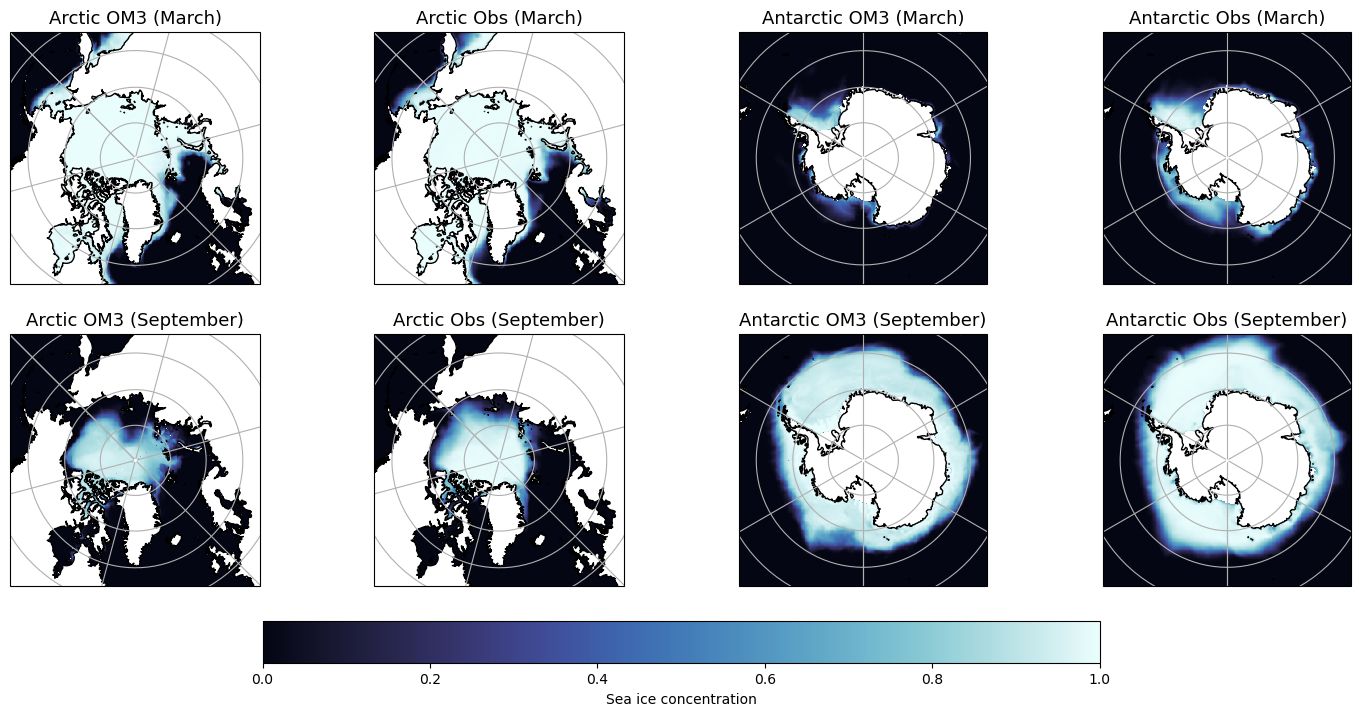

In [29]:
def plot_concentration_map(ax, crs, data, extent, title):
    im = ax.pcolormesh(data.x, data.y, data, transform=crs, cmap=cmo.ice, vmin=0, vmax=1)
    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines()
    ax.gridlines()
    ax.set_title(title, font)
    return im

# OM3 land mask on each NSIDC grid: the regridders exclude masked (land) source
# cells, so destination cells fed only by land come out as 0 rather than NaN.
# Regridding a field of ones gives the ocean fraction -- blank out land the
# same way the observations are (NaN), using the model's own coastline.
ocean_native = xr.ones_like(sic_native.isel(time=0))
sh_model_ocean = regridder_sh(ocean_native).assign_coords(x=sh_ancillary.x, y=sh_ancillary.y).compute() > 0.5
nh_model_ocean = regridder_nh(ocean_native).assign_coords(x=nh_ancillary.x, y=nh_ancillary.y).compute() > 0.5

# rows: March, September -- columns: Arctic OM3, Arctic Obs, Antarctic OM3, Antarctic Obs
panels = [
    (nh_crs, nh_model_clim.sel(month=3).where(nh_model_ocean), nh_extent, "Arctic OM3 (March)"),
    (nh_crs, nh_obs_clim.sel(month=3), nh_extent, "Arctic Obs (March)"),
    (sh_crs, sh_model_clim.sel(month=3).where(sh_model_ocean), sh_extent, "Antarctic OM3 (March)"),
    (sh_crs, sh_obs_clim.sel(month=3), sh_extent, "Antarctic Obs (March)"),
    (nh_crs, nh_model_clim.sel(month=9).where(nh_model_ocean), nh_extent, "Arctic OM3 (September)"),
    (nh_crs, nh_obs_clim.sel(month=9), nh_extent, "Arctic Obs (September)"),
    (sh_crs, sh_model_clim.sel(month=9).where(sh_model_ocean), sh_extent, "Antarctic OM3 (September)"),
    (sh_crs, sh_obs_clim.sel(month=9), sh_extent, "Antarctic Obs (September)"),
]

fig = plt.figure(figsize=(18, 9))
axes = []
for i, (crs, data, extent, title) in enumerate(panels, start=1):
    ax = fig.add_subplot(2, 4, i, projection=crs)
    im = plot_concentration_map(ax, crs, data, extent, title)
    axes.append(ax)

fig.colorbar(im, ax=axes, orientation="horizontal", shrink=0.6, pad=0.05,
             label="Sea ice concentration")

mkmd.savefig(fig, "Sea Ice Concentration", "March and September sea ice concentration climatology for OM3 and observations, regridded to the NSIDC polar-stereographic grid for each hemisphere.", dpi=300)
plt.show()

In [30]:
client.close()